In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Definir las variables de entrada y salida difusas
demanda_predicha = ctrl.Antecedent(np.arange(0, 1001, 1), 'demanda_predicha')
impacto_promocion = ctrl.Antecedent(np.arange(0, 1001, 1), 'impacto_promocion')
inventario_rfid = ctrl.Antecedent(np.arange(0, 1001, 1), 'inventario_rfid')

valoracion_situacion = ctrl.Consequent(np.arange(0, 11, 1), 'valoracion_situacion')

# Definir las funciones de membresía para cada variable
demanda_predicha['baja'] = fuzz.trimf(demanda_predicha.universe, [0, 0, 500])
demanda_predicha['media'] = fuzz.trimf(demanda_predicha.universe, [250, 500, 750])
demanda_predicha['alta'] = fuzz.trimf(demanda_predicha.universe, [500, 1000, 1000])

impacto_promocion['bajo'] = fuzz.trimf(impacto_promocion.universe, [0, 0, 500])
impacto_promocion['medio'] = fuzz.trimf(impacto_promocion.universe, [250, 500, 750])
impacto_promocion['alto'] = fuzz.trimf(impacto_promocion.universe, [500, 1000, 1000])

inventario_rfid['bajo'] = fuzz.trimf(inventario_rfid.universe, [0, 0, 500])
inventario_rfid['medio'] = fuzz.trimf(inventario_rfid.universe, [250, 500, 750])
inventario_rfid['alto'] = fuzz.trimf(inventario_rfid.universe, [500, 1000, 1000])

valoracion_situacion['baja'] = fuzz.trimf(valoracion_situacion.universe, [0, 0, 5])
valoracion_situacion['media'] = fuzz.trimf(valoracion_situacion.universe, [2, 5, 8])
valoracion_situacion['alta'] = fuzz.trimf(valoracion_situacion.universe, [5, 10, 10])


e:\fusion_datos\taller final\venv\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


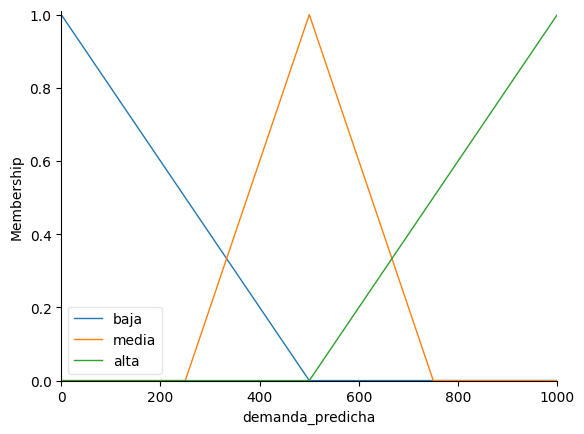

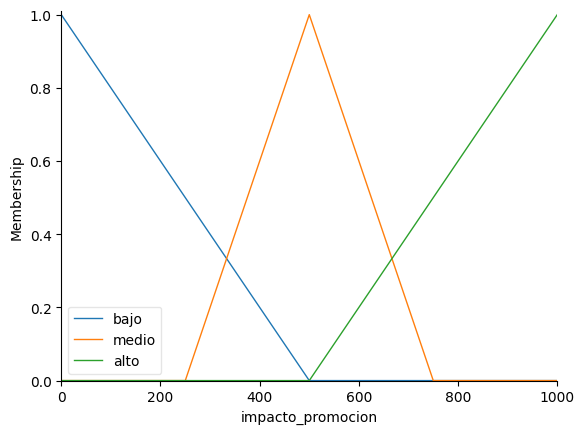

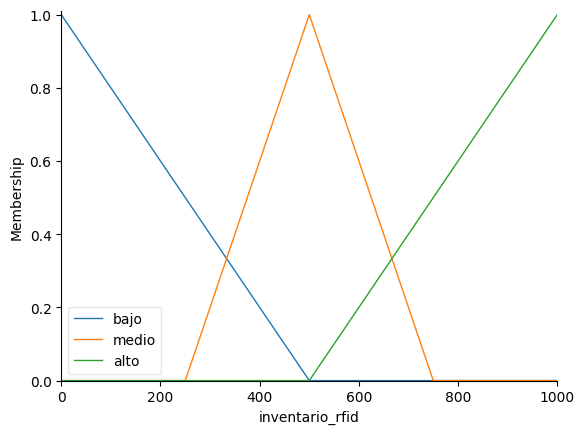

In [2]:

demanda_predicha.view()
impacto_promocion.view()
inventario_rfid.view()

In [3]:
# Crear las reglas difusas
rules = []

# Generando todas las combinaciones posibles para 3 variables con 3 estados cada una
for demanda_level in ['baja', 'media', 'alta']:
    for impacto_level in ['bajo', 'medio', 'alto']:
        for inventario_level in ['bajo', 'medio', 'alto']:
            if demanda_level == 'alta' or impacto_level == 'alto' or inventario_level == 'bajo':
                valoracion_output = 'alta'
            elif demanda_level == 'media' and impacto_level == 'medio' and inventario_level == 'medio':
                valoracion_output = 'media'
            else:
                valoracion_output = 'baja'
            
            # Crear y añadir la regla
            rule = ctrl.Rule(demanda_predicha[demanda_level] & impacto_promocion[impacto_level] & inventario_rfid[inventario_level], valoracion_situacion[valoracion_output])
            rules.append(rule)



In [4]:
cont=0
for rule in rules:
    cont+=1
    print(rule)
print(cont)

IF (demanda_predicha[baja] AND impacto_promocion[bajo]) AND inventario_rfid[bajo] THEN valoracion_situacion[alta]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (demanda_predicha[baja] AND impacto_promocion[bajo]) AND inventario_rfid[medio] THEN valoracion_situacion[baja]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (demanda_predicha[baja] AND impacto_promocion[bajo]) AND inventario_rfid[alto] THEN valoracion_situacion[baja]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (demanda_predicha[baja] AND impacto_promocion[medio]) AND inventario_rfid[bajo] THEN valoracion_situacion[alta]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (demanda_predicha[baja] AND impacto_promocion[medio]) AND inventario_rfid[medio] THEN valoracion_situacion[baja]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (demanda_predicha[baja] AND impacto_promocion[medio]) AND inventario_rfid[alto] THEN valoraci

In [5]:
# Crear el sistema de control difuso
valoracion_ctrl = ctrl.ControlSystem(rules)
valoracion = ctrl.ControlSystemSimulation(valoracion_ctrl)

In [6]:
import pandas as pd

# Cargar las predicciones
predicciones_demanda = pd.read_csv('predicciones_demanda_clasificador.csv')
predicciones_impacto_promocion = pd.read_csv('predicciones_inventario_necesario.csv')
predicciones_inventario_rfid = pd.read_csv('predicciones_inventario_rfid.csv')

# Inicializar la lista para almacenar las valoraciones de la situación
valoraciones = []

# Aplicar el FIS a cada conjunto de predicciones
for i in range(len(predicciones_demanda)):
    valoracion.input['demanda_predicha'] = predicciones_demanda['Demanda_Predicha'][i]
    valoracion.input['impacto_promocion'] = predicciones_impacto_promocion['Inventario_Necesario'][i]
    valoracion.input['inventario_rfid'] = predicciones_inventario_rfid['Inventario_RFID'][i]
    
    # Calcular la valoración de la situación
    valoracion.compute()
    
    # Almacenar la valoración
    valoraciones.append(valoracion.output['valoracion_situacion'])

# Guardar las valoraciones en un archivo CSV
valoraciones_df = pd.DataFrame({'Valoracion_Situacion': valoraciones})
valoraciones_df.to_csv('valoraciones_situacion.csv', index=False)

print("Valoraciones de la situación guardadas en 'valoraciones_situacion.csv'")


Valoraciones de la situación guardadas en 'valoraciones_situacion.csv'


In [7]:
# predicciones_demanda.info()
# predicciones_impacto_promocion.info()
# predicciones_inventario_rfid.info()
valoraciones_df.info()
valoraciones_df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 1 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Valoracion_Situacion  2000 non-null   float64
dtypes: float64(1)
memory usage: 15.8 KB


,Valoracion_Situacion
0,8.333333
1,8.333333
2,8.333333
3,8.333333
4,8.333333
...,...
1995,8.333333
1996,8.333333
1997,8.333333
1998,8.333333


In [8]:
from pyds import MassFunction

# Cargar las valoraciones
valoraciones_df = pd.read_csv('valoraciones_situacion.csv')

# Definir las funciones de masa iniciales
mass_functions = []

for i in range(len(valoraciones_df)):
    valoracion = valoraciones_df['Valoracion_Situacion'][i]
    
    if valoracion <= 3.33:
        mass_function = MassFunction({'baja': 1.0})
    elif valoracion <= 6.66:
        mass_function = MassFunction({'media': 1.0})
    else:
        mass_function = MassFunction({'alta': 1.0})
    
    mass_functions.append(mass_function)

# Combinar las funciones de masa utilizando la regla de combinación de Dempster
combined_mass = mass_functions[0]
for mass_function in mass_functions[1:]:
    combined_mass = combined_mass & mass_function

# Obtener la creencia, plausibilidad y probabilidad pignística de la valoración final
belief = combined_mass.bel({'baja', 'media', 'alta'})
plausibility = combined_mass.pl({'baja', 'media', 'alta'})
pignistic = combined_mass.pignistic()

print(f"Creencia: {belief}")
print(f"Plausibilidad: {plausibility}")
print(f"Probabilidad Pignística: {pignistic}")

# Guardar los resultados en un archivo CSV
resultados_df = pd.DataFrame({'Creencia': [belief], 'Plausibilidad': [plausibility], 'Probabilidad_Pignistica': [pignistic]})
resultados_df.to_csv('resultados_dempster_shafer.csv', index=False)

print("Resultados de Dempster-Shafer guardados en 'resultados_dempster_shafer.csv'")


Creencia: 0.0
Plausibilidad: 0.0
Probabilidad Pignística: {{'l'}:0.3333333333333333; {'t'}:0.3333333333333333; {'a'}:0.3333333333333333}
Resultados de Dempster-Shafer guardados en 'resultados_dempster_shafer.csv'
